**Libraries**

In [1]:
import pandas as pd
from pathlib import Path

**EDA**

In [2]:
### Merging tables
csv_dir = Path("../data/raw")

for file in sorted(csv_dir.glob("*.csv")):
    globals()[file.stem] = pd.read_csv(file, low_memory=False)
    print(f"{file.stem} has been initialized")

application_categories has been initialized
application_developers has been initialized
application_genres has been initialized
application_platforms has been initialized
application_publishers has been initialized
applications has been initialized
categories has been initialized
developers has been initialized
genres has been initialized
platforms has been initialized
publishers has been initialized
reviews has been initialized


In [3]:
apps = applications
del applications

In [4]:
apps['appid'].duplicated().sum()

np.int64(0)

In [5]:
raw_release_date = apps["release_date"].copy()

In [6]:
apps["release_date"] = pd.to_datetime(apps["release_date"], errors="coerce")

In [7]:
bridges = {
    "categories": application_categories,
    "developers": application_developers,
    "genres": application_genres,
    "platforms": application_platforms,
    "publishers": application_publishers,
}
for name, bdf in bridges.items():
    dups = bdf.duplicated().sum()
    assert dups == 0, f"Duplicate pairs in {name}: {dups}"
print("All 5 bridge tables have 0 duplicate (appid, fk_id) pairs.")

All 5 bridge tables have 0 duplicate (appid, fk_id) pairs.


In [8]:
categories.columns

Index(['id', 'name'], dtype='str')

In [9]:
application_categories.columns

Index(['appid', 'category_id'], dtype='str')

In [10]:
### Joining Categories
cat_agg = (
    application_categories
    .merge(categories, left_on = "category_id", right_on="id", how = 'left', validate = 'many_to_one')
    .groupby("appid")
    .agg(
        n_cats = ("id", "count"),
        cats = ("name", list),
    )
)

df = apps.merge(
    cat_agg, on="appid", how="left",validate="one_to_one"
)
assert len(df) == 239664

In [11]:
developers.columns

Index(['id', 'name'], dtype='str')

In [12]:
application_developers.columns

Index(['appid', 'developer_id'], dtype='str')

In [13]:
### Joining Developers
devs_agg = (
    application_developers
    .merge(developers, left_on="developer_id", right_on="id",how='left',validate='m:1')
    .groupby('appid')
    .agg(
        n_devs = ("id", "count"),
        devs = ("name", list),
    )
)

df = df.merge(
    devs_agg, on="appid",how="left",validate='1:1'
)
assert len(df) == 239664

In [14]:
### Joining Genres
genres_agg = (
    application_genres
    .merge(genres, left_on="genre_id", right_on="id", how="left", validate="m:1")
    .groupby("appid")
    .agg(
        n_genres=("id", "count"),
        genres=("name", list),
    )
)

df = df.merge(
    genres_agg, on="appid", how="left", validate="1:1"
)
assert len(df) == 239664


### Joining Platforms
plats_agg = (
    application_platforms
    .merge(platforms, left_on="platform_id", right_on="id", how="left", validate="m:1")
    .groupby("appid")
    .agg(
        n_platforms=("id", "count"),
        platforms=("name", list),
    )
)

df = df.merge(
    plats_agg, on="appid", how="left", validate="1:1"
)
assert len(df) == 239664


### Joining Publishers
pubs_agg = (
    application_publishers
    .merge(publishers, left_on="publisher_id", right_on="id", how="left", validate="m:1")
    .groupby("appid")
    .agg(
        n_pubs=("id", "count"),
        pubs=("name", list),
    )
)

df = df.merge(
    pubs_agg, on="appid", how="left", validate="1:1"
)
assert len(df) == 239664

In [15]:
reviews.isna().mean()

recommendationid                  0.000000
appid                             0.000000
author_steamid                    0.000000
author_num_games_owned            0.000000
author_num_reviews                0.000000
author_playtime_forever           0.000003
author_playtime_last_two_weeks    0.000003
author_playtime_at_review         0.170641
author_last_played                0.000003
language                          0.000000
review_text                       0.000743
timestamp_created                 0.000000
timestamp_updated                 0.000000
voted_up                          0.000000
votes_up                          0.000000
votes_funny                       0.000000
weighted_vote_score               0.000000
comment_count                     0.000000
steam_purchase                    0.000000
received_for_free                 0.000000
written_during_early_access       0.000000
created_at                        0.000000
updated_at                        0.000000
dtype: floa

In [16]:
### Joining Reviews (EDA diagnostics only)
reviews_agg = reviews.groupby("appid").agg(
    eda_review_cnt=("recommendationid", "count"),
    eda_pos_count=("voted_up", "sum"),
    eda_pos_rate=("voted_up", "mean"),
    eda_first_review_ts=("timestamp_created", "min"),
    eda_last_review_ts=("timestamp_created", "max"),
)

df = df.merge(
    reviews_agg, on="appid", how="left", validate="1:1"
)
assert len(df) == 239664

count_cols = [
    "n_cats", "n_devs", "n_genres", "n_platforms", "n_pubs",
    "eda_review_cnt", "eda_pos_count"
]
df[count_cols] = df[count_cols].fillna(0).astype(int)

In [17]:
(df["eda_review_cnt"] > 0).sum()

np.int64(117311)

In [18]:
df["eda_pos_rate"].isna().sum()

np.int64(122353)

In [19]:
for col in ["cats", "devs", "genres", "platforms", "pubs"]: df[col] = df[col].apply(lambda x: x if isinstance(x, list) else [])

In [20]:
### Unparseable raw release_date values
parsed_ok = apps["release_date"].notna()
print("Unparseable / NaT release_date rows:", (~parsed_ok).sum())
print("Sample raw values for NaT rows:\n", raw_release_date[~parsed_ok].value_counts(dropna=False).head(5))

### Review scrape cutoff vs app metadata scrape cutoff
latest_review = pd.to_datetime(reviews["timestamp_created"], unit="s").max()
latest_app_update = pd.to_datetime(df["updated_at"], errors="coerce").max().tz_localize(None)
print("\nLatest review timestamp (reviews cutoff):", latest_review)
print("Latest app updated_at (apps cutoff):     ", latest_app_update)

### Step-by-step filtering
s0 = df
s1 = s0.query("type == 'game'")
s2 = s1[s1["release_date"].notna()]
s3 = s2.query("release_date >= '2003-09-12'")
df_games = s3.query("release_date <= @latest_review").copy()
df_games["release_year"] = df_games["release_date"].dt.year

print(f"\n0. All rows in df:                 {len(s0):,}")
print(f"1. Keep type == 'game':            {len(s1):,}  (-{len(s0)-len(s1):,})")
print(f"2. Valid release_date (not NaT):   {len(s2):,}  (-{len(s1)-len(s2):,})")
print(f"3. Release >= 2003-09-12:          {len(s3):,}  (-{len(s2)-len(s3):,})")
print(f"4. Release <= {latest_review.date()}:        {len(df_games):,}  (-{len(s3)-len(df_games):,})")

Unparseable / NaT release_date rows: 36855
Sample raw values for NaT rows:
 release_date
NaN    36855
Name: count, dtype: int64

Latest review timestamp (reviews cutoff): 2025-09-06 14:37:00
Latest app updated_at (apps cutoff):      2025-09-29 06:05:08.643993

0. All rows in df:                 239,664
1. Keep type == 'game':            150,279  (-89,385)
2. Valid release_date (not NaT):   115,796  (-34,483)
3. Release >= 2003-09-12:          115,779  (-17)
4. Release <= 2025-09-06:        114,449  (-1,330)


<Axes: >

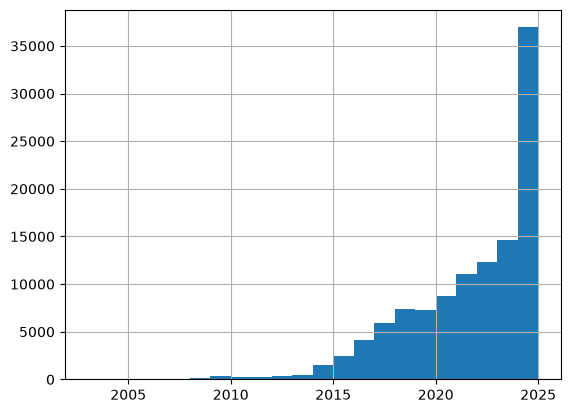

In [21]:
import matplotlib.pyplot as plt

df_games['release_year'].hist(bins = 22)

release_year
2016     4141
2017     5926
2018     7438
2019     7254
2020     8791
2021    11066
2022    12311
2023    14664
2024    20203
2025    16744
Name: count, dtype: int64


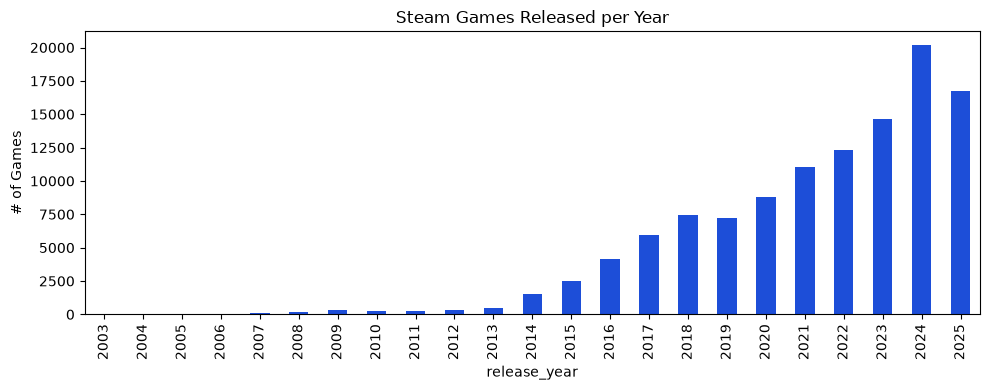

In [22]:
year_counts = df_games["release_year"].value_counts().sort_index()
print(year_counts.tail(10))

year_counts.plot(kind="bar", figsize=(10, 4), color="#1D4ED8", title="Steam Games Released per Year")
plt.ylabel("# of Games")
plt.tight_layout()

### Inclusion Criteria (`df_games`)
- **`type == 'game'`**: Excludes DLCs, demos, soundtracks, and videos.
- **`release_date` valid & `>= 2003-09-12`**: Drops `NaT`/unreleased pages and pre-Steam/epoch (`1969-12-31`) anomalies.
- **`release_date <= 2025-09-06`**: Excludes releases beyond the `reviews.csv` scrape cutoff.
- **Result**: 114,449 released games retained out of 239,664 raw rows.

**Right-Censoring + Exposure-Time Bias**

In [23]:
df_games.dtypes

appid                             int64
name                                str
type                                str
is_free                            bool
release_date             datetime64[us]
required_age                        str
short_description                   str
supported_languages                 str
header_image                        str
background                          str
metacritic_score                float64
recommendations_total           float64
mat_supports_windows               bool
mat_supports_mac                   bool
mat_supports_linux                 bool
mat_initial_price               float64
mat_final_price                 float64
mat_discount_percent            float64
mat_currency                        str
mat_achievement_count           float64
mat_pc_os_min                       str
mat_pc_processor_min                str
mat_pc_memory_min                   str
mat_pc_graphics_min                 str
mat_pc_os_rec                       str


In [24]:
df_games.groupby('release_year').agg(
    mean = ('eda_review_cnt', 'mean'),
    median = ('eda_review_cnt', 'median'),
    p90 = ('eda_review_cnt', lambda x: x.quantile(0.9)),
    max_cumsum = ('eda_review_cnt', 'max')
)

,mean,median,p90,max_cumsum
release_year,,,,
2003,1.000000,1.0,1.0,1
2004,0.000000,0.0,0.0,0
2005,26.428571,18.0,64.4,95
2006,16.619048,2.0,68.8,100
2007,24.678571,7.5,83.1,100
2008,18.364238,5.0,56.0,100
2009,15.244300,4.0,59.8,100
2010,18.429167,3.0,74.5,100
2011,20.321429,4.0,85.9,100


In [25]:
print("Games hitting the 100-review cap:", (df_games["eda_review_cnt"] == 100).sum())
print("Games with recommendations_total populated:", df_games["recommendations_total"].notna().sum())

df_games.loc[df_games["recommendations_total"].notna(), ["name", "release_year", "eda_review_cnt", "recommendations_total"]].sort_values("recommendations_total", ascending=False).head(5)

Games hitting the 100-review cap: 2182
Games with recommendations_total populated: 19787


,name,release_year,eda_review_cnt,recommendations_total
4935,Grand Theft Auto V Legacy,2015,100,1835735.0
24201,PUBG: BATTLEGROUNDS,2017,100,1746923.0
9620,Tom Clancy's Rainbow Six® Siege X,2015,100,1213861.0
2058,Terraria,2011,100,1143314.0
4193,Rust,2018,100,1043371.0


Reviews date range: 2010-10-19 10:04:22 to 2025-09-06 14:37:00
Sample timestamps:
 0   2014-05-02 19:46:05
1   2021-09-26 16:33:12
2   2021-09-26 17:00:31
Name: timestamp_created, dtype: datetime64[us]


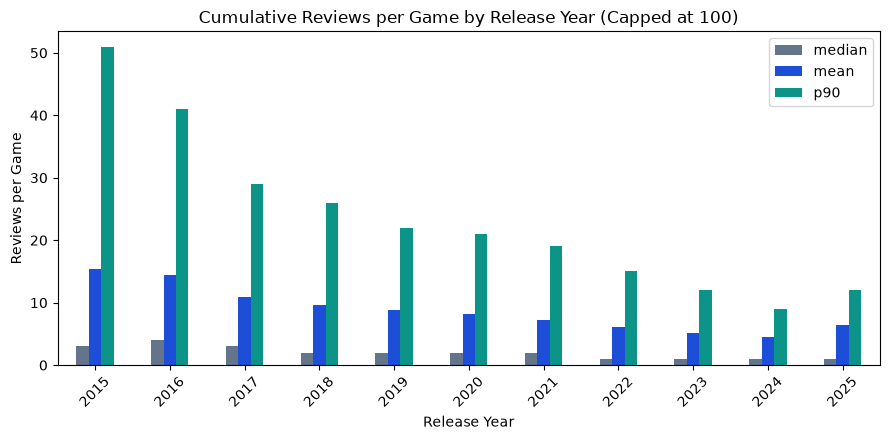

In [26]:
import numpy as np

review_dt = pd.to_datetime(reviews["timestamp_created"], unit="s")
print("Reviews date range:", review_dt.min(), "to", review_dt.max())
print("Sample timestamps:\n", review_dt.head(3))

cohort = df_games[df_games["release_year"].between(2015, 2025)].copy()
stats = cohort.groupby("release_year")["eda_review_cnt"].agg(
    median="median",
    mean="mean",
    p90=lambda s: np.percentile(s, 90),
)

ax = stats.plot(kind="bar", figsize=(9, 4.5), color=["#64748B", "#1D4ED8", "#0D9488"])
ax.set_title("Cumulative Reviews per Game by Release Year (Capped at 100)")
ax.set_ylabel("Reviews per Game")
ax.set_xlabel("Release Year")
ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
Path("../reports/figures").mkdir(parents=True, exist_ok=True)
plt.savefig("../reports/figures/exposure_time_bias.png", dpi=150)
plt.show()